# Sensitivity analysis and parameter estimation for a STAT1/STAT3 signaling model

This notebook is the worked example for Module 3. We take a rule-based model of cytokine signaling through STAT1 and STAT3, pretend we do not know its rate constants, and ask how much we can learn about them from time courses of pSTAT1 and pSTAT3.

The steps are the ones you would follow with real data:

1. Write down a plausible **range** for each rate constant, based only on what kind of process it describes.
2. Generate **synthetic data** from the model with a known set of parameters (the "true" values), plus measurement noise.
3. Use **sensitivity analysis** to find which parameters affect pSTAT1 and pSTAT3, locally (near one parameter set) and globally (across the whole range).
4. Use the **Fisher information matrix** to predict which parameters, or combinations of parameters, the data can constrain.
5. **Fit** the rate constants by multistart optimization, starting with no knowledge beyond the ranges, and compare the estimates with the true values.
6. Compute **profile likelihoods** to see which estimates are reliable.
7. Try a common shortcut: fix the insensitive parameters.
8. Ask whether **another experiment** would help.

Because the data are synthetic, we can check every estimate against the truth. With real data you cannot, and the sensitivity and identifiability analyses are how you find out what your estimates mean.

We assume the copy numbers of receptor, STAT1, STAT3, and the *SOCS3* gene, and the ligand concentration, are known (for example from quantitative proteomics), and estimate only the 18 rate constants.

Simulations use [bngsim](https://bngsim.readthedocs.io); fitting uses [pyPESTO](https://github.com/icb-dcm/pypesto). Run the notebook from inside `notebooks/`. The whole notebook takes about ten minutes; the fitting cells take the longest.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc
import bngsim
import pypesto
import pypesto.optimize as optimize
import pypesto.profile as profile
import pypesto.visualize as visualize
import logging, warnings
logging.getLogger('pypesto').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=FutureWarning)

plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

# Figures for the lecture slides are saved here if the folder exists
FIGDIR = '../Slides/module3-estimation/figures'
def save_fig(name):
    if os.path.isdir(FIGDIR):
        plt.savefig(os.path.join(FIGDIR, name + '.pdf'), bbox_inches='tight')

## 1. The model

`stat1_stat3.bngl` extends version 3 of the Module 2 model (`stat_rbm3_socs_site.bngl`) to two STATs:

- Ligand binds the receptor; STAT1 and STAT3 **compete** for the same docking site on a ligand-bound receptor.
- The receptor kinase phosphorylates whichever STAT is docked, unless SOCS3 occupies the receptor's SOCS site.
- Phosphorylated STATs leave the receptor and are dephosphorylated by phosphatases.
- Only pSTAT3 binds the *SOCS3* promoter, so STAT3 drives the negative feedback that shuts off both STATs.

This is roughly the situation for IL-6, which signals mainly through STAT3 but also activates STAT1.

### Units: copy numbers

Unlike the Module 1 and 2 models, this one counts **molecules per cell** and measures time in seconds. Copy numbers are what quantitative proteomics and flow cytometry report, and they are what a stochastic simulation needs. Rate constants, on the other hand, are usually measured and quoted in concentration units, so the model takes them in standard units and converts:

- A first-order rate constant (s⁻¹) needs no conversion.
- A second-order rate constant $k$ in M⁻¹ s⁻¹ becomes a rate per pair of molecules, $k / (N_A V)$, where $V$ is the volume in which the two molecules meet. Ligand meets receptors from the medium, so $V$ is the medium volume per cell, $V_\text{ext} = 1/\rho_\text{cell}$. STAT docking and SOCS3 binding happen in the cytoplasm ($V_\text{cyt}$); pSTAT3 binds the promoter in the nucleus ($V_\text{nuc}$).
- A concentration $c$ (M) in volume $V$ becomes a copy number $c N_A V$. The ligand concentration $L$ in the medium becomes $L N_A V_\text{ext}$ ligand molecules per cell.

In [2]:
model = bngsim.Model.from_bngl('../models/stat1_stat3.bngl')
sim = bngsim.Simulator(model, method='ode')
print(model.n_species, 'species,', model.n_reactions, 'reactions')

observables = ['pSTAT1', 'pSTAT3']
known = ['NA', 'Vcyt', 'Vnuc', 'cell_dens', 'L_conc', 'R0', 'S1_0', 'S3_0', 'G0']   # treated as known
rates = [p for p in model.primary_param_names if p not in known]
true_values = np.array([model.get_param(p) for p in rates])   # used to make the data, then "forgotten"
print(len(rates), 'rate constants:', rates)

# The conversions, evaluated by the model
NA, Vext, Vcyt = model.get_param('NA'), model.get_param('Vext'), model.get_param('Vcyt')
print(f"\nmedium volume per cell: Vext = {Vext:.0e} L")
print(f"ligand at {model.get_param('L_conc'):.0e} M: {model.get_param('L0'):.2e} molecules per cell")
print(f"kon   = {model.get_param('kon'):.0e} /M/s  ->  {model.get_param('kon_m'):.2e} /molecule/s  (in Vext)")
print(f"kS3on = {model.get_param('kS3on'):.0e} /M/s  ->  {model.get_param('kS3on_m'):.2e} /molecule/s  (in Vcyt)")
print(f"STAT3: {model.get_param('S3_0'):.0e} molecules in {Vcyt:.0e} L = {model.get_param('S3_0') / (NA * Vcyt) * 1e6:.2f} µM")

29 species, 65 reactions
18 rate constants: ['kon', 'koff', 'kS1on', 'kS1off', 'kS3on', 'kS3off', 'kact', 'kdiss', 'kS1dephos', 'kS3dephos', 'kGon', 'kGoff', 'ktx', 'kmdeg', 'ktl', 'kSOCSdeg', 'kSOCSon', 'kSOCSoff']

medium volume per cell: Vext = 1e-09 L
ligand at 1e-09 M: 6.02e+05 molecules per cell
kon   = 1e+07 /M/s  ->  1.66e-08 /molecule/s  (in Vext)
kS3on = 1e+06 /M/s  ->  1.66e-06 /molecule/s  (in Vcyt)
STAT3: 2e+05 molecules in 1e-12 L = 0.33 µM


### Parameter ranges

Before fitting, we need to say where each parameter could plausibly lie. We do this by **class of process**, not by parameter, so the ranges carry no information about the particular values used to make the data:

| class | parameters | range |
|---|---|---|
| association | `kon`, `kS1on`, `kS3on`, `kGon`, `kSOCSon` | $10^{4}$ to $10^{8}$ M⁻¹ s⁻¹ |
| dissociation | `koff`, `kS1off`, `kS3off`, `kGoff`, `kSOCSoff` | $10^{-4}$ to $10^{1}$ s⁻¹ |
| catalysis and synthesis | `kact`, `kdiss`, `ktx`, `ktl` | $10^{-3}$ to $10^{1}$ s⁻¹ |
| decay and dephosphorylation | `kS1dephos`, `kS3dephos`, `kmdeg`, `kSOCSdeg` | $10^{-5}$ to $10^{-2}$ s⁻¹ |

The association range runs from slow protein–protein binding up to near the diffusion limit. Dissociation rates from $10^{-4}$ to $10$ s⁻¹ cover complex lifetimes from a tenth of a second to a few hours. Decay rates from $10^{-5}$ to $10^{-2}$ s⁻¹ are half-lives from about a minute to a day.

We work with $\log_{10}$ of each parameter throughout. Rate constants vary over orders of magnitude, and a step of 0.1 in $\log_{10} k$ means the same relative change whether $k$ is 0.001 or 1000.

In [3]:
class_ranges = {'association': (4, 8), 'dissociation': (-4, 1),
                'catalysis': (-3, 1), 'decay': (-5, -2)}
param_class = {
    'kon': 'association', 'kS1on': 'association', 'kS3on': 'association',
    'kGon': 'association', 'kSOCSon': 'association',
    'koff': 'dissociation', 'kS1off': 'dissociation', 'kS3off': 'dissociation',
    'kGoff': 'dissociation', 'kSOCSoff': 'dissociation',
    'kact': 'catalysis', 'kdiss': 'catalysis', 'ktx': 'catalysis', 'ktl': 'catalysis',
    'kS1dephos': 'decay', 'kS3dephos': 'decay', 'kmdeg': 'decay', 'kSOCSdeg': 'decay'}

lb = np.array([class_ranges[param_class[p]][0] for p in rates], dtype=float)
ub = np.array([class_ranges[param_class[p]][1] for p in rates], dtype=float)
x_true = np.log10(true_values)        # log10 of the true values
x_center = (lb + ub) / 2              # our best guess with no other information

pd.DataFrame({'class': [param_class[p] for p in rates], 'log10 lower': lb,
              'log10 upper': ub, 'log10 true': x_true.round(2)}, index=rates)

,class,log10 lower,log10 upper,log10 true
kon,association,4.0,8.0,7.00
koff,dissociation,-4.0,1.0,-3.00
kS1on,association,4.0,8.0,5.48
kS1off,dissociation,-4.0,1.0,0.00
kS3on,association,4.0,8.0,6.00
kS3off,dissociation,-4.0,1.0,-0.30
kact,catalysis,-3.0,1.0,-0.70
kdiss,catalysis,-3.0,1.0,-0.30
kS1dephos,decay,-5.0,-2.0,-2.70
kS3dephos,decay,-5.0,-2.0,-2.52


A helper to run the model with a given set of rate constants. Remember that a bngsim run starts from the model's current state, so we call `model.reset()` before every run. Times are in seconds; we plot in minutes.

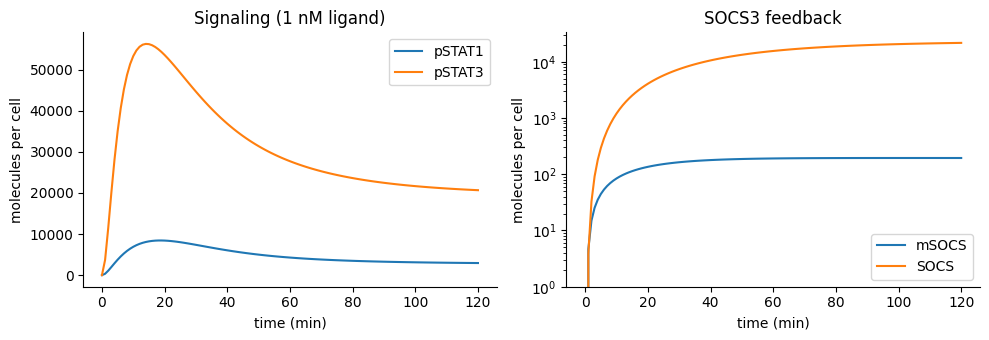

In [4]:
def run_model(x, names=rates, L_conc=1e-9, times=np.linspace(0, 7200, 121), simulator=sim):
    """Simulate with log10 parameter values x for the parameters in names."""
    model.set_params(dict(zip(names, 10.0 ** np.asarray(x))))
    model.set_param('L_conc', L_conc)
    model.reset()
    return simulator.run(sample_times=list(times))

res = run_model(x_true)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for o in observables:
    ax[0].plot(res.time / 60, res.observables[o], label=o)
for o in ['mSOCS', 'SOCS']:
    ax[1].plot(res.time / 60, res.observables[o], label=o)
ax[1].set_yscale('log'); ax[1].set_ylim(1, None)
for a in ax:
    a.set_xlabel('time (min)'); a.set_ylabel('molecules per cell'); a.legend()
ax[0].set_title('Signaling (1 nM ligand)'); ax[1].set_title('SOCS3 feedback')
plt.tight_layout(); save_fig('model_dynamics')

## 2. Synthetic data

We "measure" pSTAT1 and pSTAT3 at 15 time points over two hours after adding 1 nM ligand. Each measurement has Gaussian noise with a standard deviation of 10% of the true value plus a floor of 200 molecules, roughly what a good quantitative assay gives.

We also generate data at two lower ligand doses (100 pM and 10 pM). We use only the 1 nM data until Section 8.

Written to stat1_stat3_data.csv


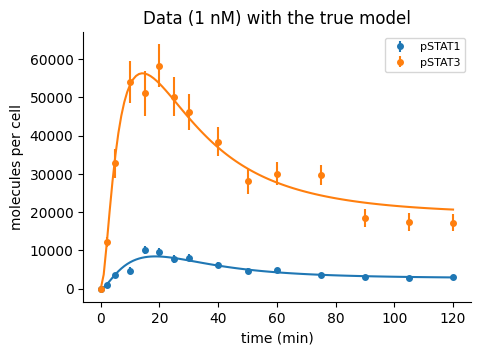

In [5]:
t_data = np.array([0, 2, 5, 10, 15, 20, 25, 30, 40, 50, 60, 75, 90, 105, 120], dtype=float) * 60
doses = [1e-9, 1e-10, 1e-11]
rng = np.random.default_rng(seed=2)

rows = []
for L in doses:
    r = run_model(x_true, L_conc=L, times=t_data)
    for o in observables:
        y = r.observables[o]
        sd = 0.1 * y + 200
        noisy = y + rng.normal(0, sd)
        noisy[0] = 0.0                 # nothing is phosphorylated before ligand is added
        for t, yi, si in zip(t_data, noisy, sd):
            rows.append({'L_conc': L, 'time': t, 'observable': o, 'value': yi, 'sd': si})
data = pd.DataFrame(rows)
data.to_csv('stat1_stat3_data.csv', index=False)
print('Written to stat1_stat3_data.csv')

def get_experiment(L):
    """Data and standard deviations for one dose, as (time x observable) arrays."""
    d = data[data.L_conc == L]
    y = np.column_stack([d[d.observable == o].value.values for o in observables])
    sd = np.column_stack([d[d.observable == o].sd.values for o in observables])
    return {'L_conc': L, 'y': y, 'sd': sd}

high_dose = get_experiment(1e-9)

def plot_data(exps, x=None, names=rates, ax=None, title=''):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 3.5))
    for e, ls in zip(exps, ['-', '--', ':']):
        for k, o in enumerate(observables):
            c = f'C{k}'
            lab = f'{o}, {e["L_conc"] * 1e12:g} pM' if len(exps) > 1 else o
            ax.errorbar(t_data / 60, e['y'][:, k], yerr=e['sd'][:, k], fmt='o', ms=4, color=c,
                        alpha=1 if ls == '-' else 0.6, label=lab)
            if x is not None:
                r = run_model(x, names, L_conc=e['L_conc'])
                ax.plot(r.time / 60, r.observables[o], ls, color=c)
    ax.set_xlabel('time (min)'); ax.set_ylabel('molecules per cell')
    ax.set_title(title); ax.legend(fontsize=8)
    return ax

plot_data([high_dose], x_true, title='Data (1 nM) with the true model')
save_fig('data_high')

## 3. Sensitivity analysis

### 3a. Local sensitivity

The local sensitivity of an output $O_i$ to a parameter $p_j$ is the normalized derivative

$$S_{ij}(t) = \frac{\partial \ln O_i(t)}{\partial \ln p_j} = \frac{p_j}{O_i(t)}\frac{\partial O_i(t)}{\partial p_j}.$$

$S_{ij} = 0.5$ means a 1% increase in $p_j$ raises $O_i$ by 0.5%. Because both sides are logarithmic, $S_{ij}$ does not depend on the units of $p_j$ or $O_i$.

We could estimate the derivatives by finite differences (rerun the model with each parameter nudged by 1%), but bngsim can integrate the **forward sensitivity equations** alongside the model, which gives the derivatives in a single run. We ask for them with `sensitivity_params`. The derivatives are taken with respect to the parameters in standard units; bngsim applies the chain rule through the unit conversions.

First, a check that the forward sensitivities agree with finite differences for two parameters:

In [6]:
sim_sens = bngsim.Simulator(model, method='ode', sensitivity_params=rates)
t_fine = np.linspace(0, 7200, 121)
r = run_model(x_true, times=t_fine, simulator=sim_sens)
dO_dp = r.output_sensitivities([f'observable:{o}' for o in observables])   # (time, observable, parameter)
O = np.column_stack([r.observables[o] for o in observables])

for p in ['kS3on', 'kS3dephos']:
    j = rates.index(p)
    x_up = x_true.copy(); x_up[j] += np.log10(1.001)
    O_up = run_model(x_up, times=t_fine).observables['pSTAT3']
    fd = (O_up - O[:, 1]) / (0.001 * true_values[j])
    print(f'{p:10s} d pSTAT3/dp at 30 min: forward sensitivity {dO_dp[30, 1, j]:.4e}, finite difference {fd[30]:.4e}')

kS3on      d pSTAT3/dp at 30 min: forward sensitivity 2.4446e-02, finite difference 2.4433e-02
kS3dephos  d pSTAT3/dp at 30 min: forward sensitivity -1.3334e+07, finite difference -1.3323e+07


Now the normalized sensitivities for all 18 parameters. We summarize each time course by its root-mean-square over time to rank the parameters.

Local sensitivities depend on where you compute them. Here we compute them at the true parameter values, which you could not do with real data (you would use your best estimate). We will see in 3b whether the conclusions hold across the whole range.

,pSTAT1,pSTAT3
kS1dephos,0.957,0.001
kS1on,0.918,0.028
kS3dephos,0.048,0.877
kact,0.825,0.632
kS1off,0.768,0.024
ktx,0.592,0.545
ktl,0.592,0.545
kS3on,0.297,0.573
kSOCSon,0.541,0.501
kSOCSoff,0.523,0.491


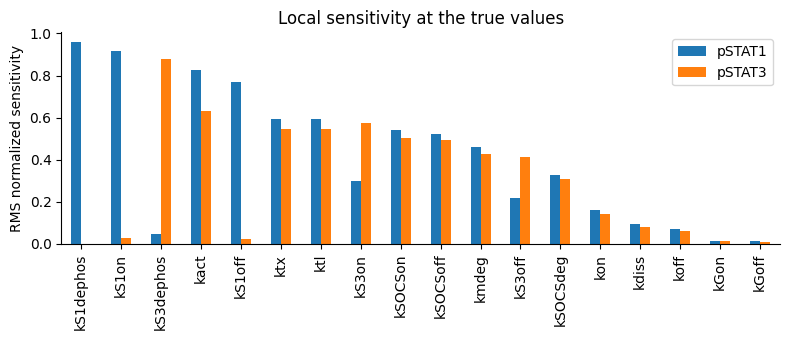

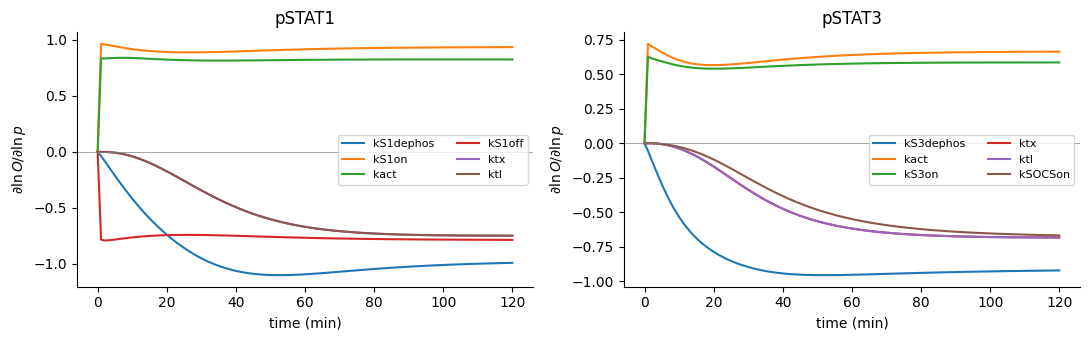

In [7]:
S_local = dO_dp * true_values[None, None, :] / np.maximum(O[:, :, None], 1e-12)
S_local[0] = 0.0                                                             # O = 0 at t = 0
S_rms = pd.DataFrame(np.sqrt(np.mean(S_local[1:] ** 2, axis=0)).T, index=rates, columns=observables)
order_local = S_rms.max(axis=1).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 3.5))
S_rms.loc[order_local].plot.bar(ax=ax)
ax.set_ylabel('RMS normalized sensitivity'); ax.set_title('Local sensitivity at the true values')
plt.tight_layout(); save_fig('local_bar')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for k, o in enumerate(observables):
    for p in S_rms[o].sort_values(ascending=False).index[:6]:
        ax[k].plot(t_fine / 60, S_local[:, k, rates.index(p)], label=p)
    ax[k].axhline(0, color='gray', lw=0.5)
    ax[k].set_xlabel('time (min)'); ax[k].set_ylabel(r'$\partial \ln O / \partial \ln p$')
    ax[k].set_title(o); ax[k].legend(fontsize=8, ncol=2)
plt.tight_layout(); save_fig('local_time')
S_rms.loc[order_local].round(3)

Things to notice:

- Each STAT's own dephosphorylation rate dominates its time course. `kS1dephos` hardly affects pSTAT3, and `kS3dephos` hardly affects pSTAT1.
- Docking (`kS1on`, `kS3on`) and kinase activity (`kact`) set the level of both responses from the start. Because the two STATs compete for the same site, `kS3on` *lowers* pSTAT1 ($S \approx -0.3$). STAT1 docking barely affects pSTAT3, since STAT3 is the main occupant of the receptors.
- The feedback parameters (`ktx`, `ktl`, `kSOCSon`, `kSOCSdeg`) matter only after about 20 min, once SOCS3 has accumulated.
- `ktx` and `ktl` have identical sensitivities. They reach the outputs only through their product, the SOCS3 synthesis rate per bound promoter.
- Promoter binding (`kGon`, `kGoff`) has no effect: at these pSTAT3 levels both *SOCS3* promoters are occupied about 99% of the time. Ligand binding (`kon`, `koff`) matters only in the first few minutes; at 1 nM, most receptors are bound within 5 min.

### 3b. Global sensitivity

Global sensitivity analysis varies all parameters at once across their ranges. We draw a Latin hypercube sample of 2000 parameter sets in $\log_{10}$ space, simulate each one, and summarize each time course by three features: the peak value, the time of the peak, and the value at 60 min.

Then we fit a linear regression of each (log) feature on the (log) parameters. With both sides standardized to zero mean and unit variance, the regression coefficients (**standardized regression coefficients**) measure how much each parameter contributes to the variation of the feature across the sample. $R^2$ tells us how much of the variation a linear model captures; the rest comes from nonlinearity and interactions between parameters.

In [8]:
n_samples = 2000
sampler = qmc.LatinHypercube(d=len(rates), seed=1)
X = qmc.scale(sampler.random(n_samples), lb, ub)
t_coarse = np.linspace(0, 7200, 61)

features, ok = [], []
t0 = time.time()
for x in X:
    try:
        r = run_model(x, times=t_coarse)
    except bngsim.SimulationError:
        ok.append(False); features.append([np.nan] * 6); continue
    f = []
    for o in observables:
        y = r.observables[o]
        f += [y.max(), t_coarse[np.argmax(y)] / 60, y[30]]
    features.append(f); ok.append(True)
ok = np.array(ok)
feature_names = ['peak pSTAT1', 'time of peak pSTAT1', 'pSTAT1 at 60 min',
                 'peak pSTAT3', 'time of peak pSTAT3', 'pSTAT3 at 60 min']
F = pd.DataFrame(np.array(features)[ok], columns=feature_names)
print(f'{n_samples} simulations in {time.time() - t0:.1f} s, {np.sum(~ok)} failed')

2000 simulations in 2.6 s, 0 failed


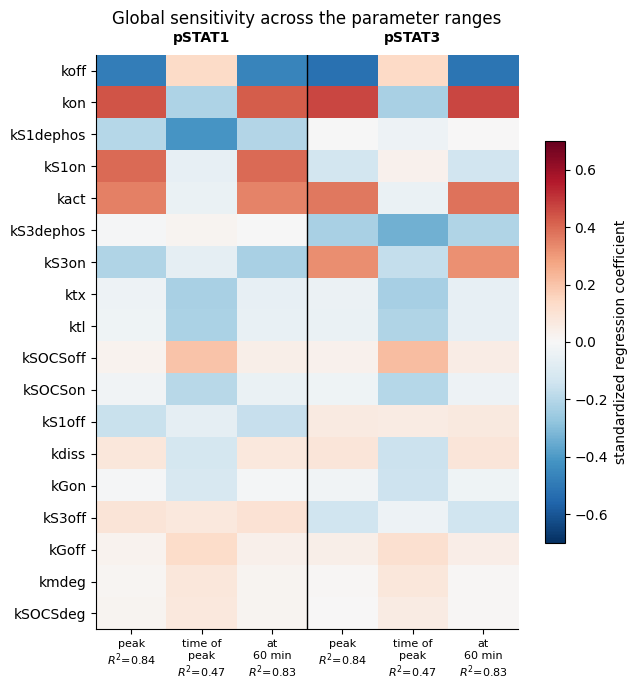

In [9]:
Xs = (X[ok] - X[ok].mean(0)) / X[ok].std(0)
src = pd.DataFrame(index=rates, columns=feature_names, dtype=float)
r2 = {}
for f in feature_names:
    y = np.log10(np.maximum(F[f].values, 1e-3))
    y = (y - y.mean()) / y.std()
    A = np.column_stack([Xs, np.ones(len(y))])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    src[f] = coef[:-1]
    r2[f] = 1 - np.sum((y - A @ coef) ** 2) / np.sum(y ** 2)

order_global = src.abs().max(axis=1).sort_values(ascending=False).index
short = ['peak', 'time of\npeak', 'at\n60 min'] * 2
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(src.loc[order_global].values, cmap='RdBu_r', vmin=-0.7, vmax=0.7, aspect='auto')
ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels([f'{s}\n$R^2$={r2[f]:.2f}' for s, f in zip(short, feature_names)], fontsize=8)
ax.axvline(2.5, color='k', lw=1)
for k, o in enumerate(observables):
    ax.text(1 + 3 * k, -0.9, o, ha='center', fontweight='bold')
ax.set_yticks(range(len(rates))); ax.set_yticklabels(order_global)
plt.colorbar(im, label='standardized regression coefficient', shrink=0.7)
ax.set_title('Global sensitivity across the parameter ranges', pad=22)
plt.tight_layout(); save_fig('global_src')

The global ranking differs from the local one in an instructive way.

- Ligand binding (`kon`, `koff`) comes out on top, although it barely mattered at the true values. Across the plausible ranges, binding is often slow or weak: with `kon` = $10^4$ M⁻¹ s⁻¹, binding at 1 nM takes more than a day, and with `koff` = 10 s⁻¹ the dissociation constant is far above 1 nM. Whenever that happens, receptor occupancy limits everything downstream. At the true values the receptors saturate within minutes, so these parameters drop out of the local analysis.
- Dephosphorylation, docking (`kS1on`, `kS3on`), and `kact` are important in both analyses.
- Some parameters with large local sensitivities, such as `kS1off` and the SOCS3 loop parameters, have small global coefficients. Their effects depend on the values of other parameters, and partly average out across the sample.
- A linear model explains the peak and the 60 min value well ($R^2 \approx 0.84$) but not the time of the peak ($R^2 \approx 0.47$), which depends on the dephosphorylation rates and the feedback loop through interactions a linear regression cannot capture.

A parameter with low sensitivity is not "unimportant" in general. It is unimportant *for these outputs, in this region of parameter space*.

## 4. What can the data tell us? The Fisher information matrix

Sensitivity tells us which parameters move the outputs. Identifiability asks a sharper question: can the *data* pin a parameter down, given the noise and given what the other parameters are doing?

For data $y_k$ with standard deviations $\sigma_k$, the Fisher information matrix (FIM) is

$$\mathrm{FIM} = J^\mathsf{T} J, \qquad J_{kj} = \frac{1}{\sigma_k}\frac{\partial y_k}{\partial \log_{10} p_j},$$

where $k$ runs over every data point. Its eigenvectors are combinations of parameters, and each eigenvalue $\lambda$ says how strongly the data constrain that combination: roughly, the standard error along an eigenvector is $1/\sqrt{\lambda}$ in $\log_{10}$ units. An eigenvalue of 100 means a combination known to within a factor of $10^{0.1} \approx 1.26$; an eigenvalue of $10^{-4}$ means it is not constrained at all.

The FIM needs only the sensitivities at the data time points, so we can compute it before fitting anything, and even before collecting data.

7 of 18 parameter combinations have eigenvalue > 1
eigenvalue -3.1e-13: ktx +0.71, ktl -0.71, kGoff +0.00
eigenvalue 5.1e-11: kGoff +0.80, kGon +0.60, koff -0.04
eigenvalue 6.1e-09: koff -0.97, kact -0.13, kGoff -0.11


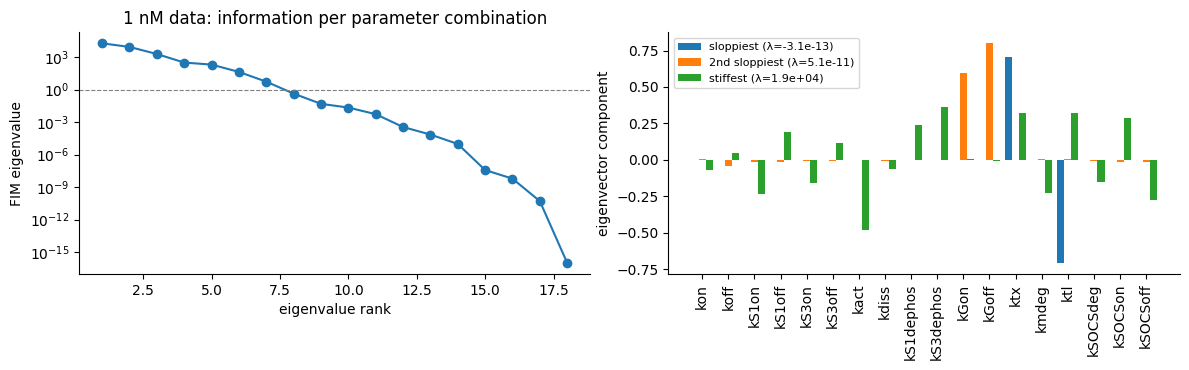

In [10]:
def jacobian(x, exp, names=rates):
    """Sensitivities of the data points (scaled by 1/sd) to log10 of each parameter."""
    s = bngsim.Simulator(model, method='ode', sensitivity_params=list(names))
    r = run_model(x, names, L_conc=exp['L_conc'], times=t_data, simulator=s)
    dy = r.output_sensitivities([f'observable:{o}' for o in observables])[1:]   # skip t = 0
    theta = 10.0 ** np.asarray(x)
    return (dy / exp['sd'][1:, :, None] * theta * np.log(10)).reshape(-1, len(names))

def fim_eigen(J):
    """Eigenvalues (ascending) and eigenvectors (columns) of the FIM."""
    return np.linalg.eigh(J.T @ J)

J_high = jacobian(x_true, high_dose)
eigvals, eigvecs = fim_eigen(J_high)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].semilogy(range(1, len(eigvals) + 1), np.maximum(eigvals[::-1], 1e-16), 'o-')
ax[0].axhline(1, color='gray', ls='--', lw=0.8)
ax[0].set_xlabel('eigenvalue rank'); ax[0].set_ylabel('FIM eigenvalue')
ax[0].set_title('1 nM data: information per parameter combination')
for shift, (i, lab) in zip([-0.27, 0, 0.27], [(0, 'sloppiest'), (1, '2nd sloppiest'), (-1, 'stiffest')]):
    ax[1].bar(np.arange(len(rates)) + shift, eigvecs[:, i], width=0.27, label=f'{lab} (λ={eigvals[i]:.1e})')
ax[1].set_xticks(range(len(rates))); ax[1].set_xticklabels(rates, rotation=90)
ax[1].set_ylabel('eigenvector component'); ax[1].legend(fontsize=8)
plt.tight_layout(); save_fig('fim_high')
print(f'{np.sum(eigvals > 1)} of {len(rates)} parameter combinations have eigenvalue > 1')
for i in range(3):
    v = eigvecs[:, i]
    top = np.argsort(-np.abs(v))[:3]
    print(f'eigenvalue {eigvals[i]:.1e}: ' + ', '.join(f'{rates[j]} {v[j]:+.2f}' for j in top))

The eigenvalues span about 17 orders of magnitude, a pattern so common in systems biology models that they are called **sloppy**. Only a handful of the 18 parameter combinations have eigenvalue above 1.

- The sloppiest direction is `ktx` − `ktl` (components +0.71 and −0.71). Increasing one and decreasing the other by the same factor leaves their product, and every output, unchanged. This is a **structural** non-identifiability: no amount of pSTAT data, however precise, can separate them.
- The next sloppiest is promoter binding (`kGon`, `kGoff`), which has no effect while the promoters are saturated.
- The stiffest direction is a mixture of the parameters with the largest sensitivities: dephosphorylation, docking, and `kact`. These are the combinations we can expect to estimate.

## 5. Fitting all 18 rate constants

We fit by minimizing $\chi^2$, the sum of squared residuals weighted by the measurement standard deviations:

$$\chi^2(\mathbf{x}) = \sum_k \left(\frac{y_k^{\text{model}}(\mathbf{x}) - y_k^{\text{data}}}{\sigma_k}\right)^2 .$$

For Gaussian noise, $\chi^2/2$ is the negative log-likelihood (up to a constant), which is what pyPESTO minimizes.

Because $\chi^2$ is a sum of squares, we can use a **least-squares** optimizer (a trust-region relative of Levenberg–Marquardt), which uses the Jacobian of the residuals. bngsim supplies that Jacobian from the forward sensitivities, so each step costs about one simulation.

The cost landscape has many local minima, so we run the optimizer from random starting points drawn uniformly from the parameter ranges (**multistart**). Nothing about the true values enters the fit.

In [11]:
def make_problem(experiments, free=rates, fixed=None):
    """pyPESTO problem for chi^2 over the given experiments.

    free  : names of the parameters to estimate (in log10)
    fixed : dict of log10 values for the parameters not estimated
    """
    free = list(free)
    fixed = fixed or {}
    s = bngsim.Simulator(model, method='ode', sensitivity_params=free)
    cache = {}

    def residuals_and_jacobian(x):
        key = tuple(x)
        if key not in cache:
            theta = 10.0 ** np.asarray(x)
            res, jac = [], []
            for e in experiments:
                model.set_params({p: 10.0 ** v for p, v in fixed.items()})
                n = e['y'][1:].size
                try:
                    r = run_model(x, free, L_conc=e['L_conc'], times=t_data, simulator=s)
                except bngsim.SimulationError:
                    res.append(np.full(n, 1e3)); jac.append(np.zeros((n, len(free))))
                    continue
                y = np.column_stack([r.observables[o] for o in observables])
                res.append(((y - e['y']) / e['sd'])[1:].ravel())
                dy = r.output_sensitivities([f'observable:{o}' for o in observables])[1:]
                jac.append((dy / e['sd'][1:, :, None] * theta * np.log(10)).reshape(-1, len(free)))
            cache.clear()
            cache[key] = (np.concatenate(res), np.vstack(jac))
        return cache[key]

    res = lambda x: residuals_and_jacobian(x)[0]
    sres = lambda x: residuals_and_jacobian(x)[1]
    objective = pypesto.Objective(
        fun=lambda x: 0.5 * np.sum(res(x) ** 2),          # negative log-likelihood (up to a constant)
        grad=lambda x: sres(x).T @ res(x),
        res=res, sres=sres)
    idx = [rates.index(p) for p in free]
    problem = pypesto.Problem(objective, lb=lb[idx], ub=ub[idx], x_names=free)
    problem.res_fun, problem.jac_fun = res, sres     # kept for the profiles in Section 6
    return problem

def chi2(problem, x):
    return 2 * problem.objective(np.asarray(x))

def multistart(problem, n_starts, seed=0):
    np.random.seed(seed)
    t0 = time.time()
    result = optimize.minimize(problem, optimize.ScipyOptimizer(method='ls_trf', options={'max_nfev': 300}),
                               n_starts=n_starts, progress_bar=False)
    fvals = np.array([r['fval'] for r in result.optimize_result.list])
    print(f'{n_starts} starts in {time.time() - t0:.0f} s; best chi2 = {2 * fvals[0]:.1f}; '
          f'{np.sum(2 * (fvals - fvals[0]) < 4)} starts within 4 of the best')
    return result

problem_high = make_problem([high_dose])
n_data = high_dose['y'][1:].size
print(f'{n_data} data points; chi2 at the true parameters = {chi2(problem_high, x_true):.1f}')

28 data points; chi2 at the true parameters = 30.3


20 starts in 145 s; best chi2 = 18.9; 17 starts within 4 of the best


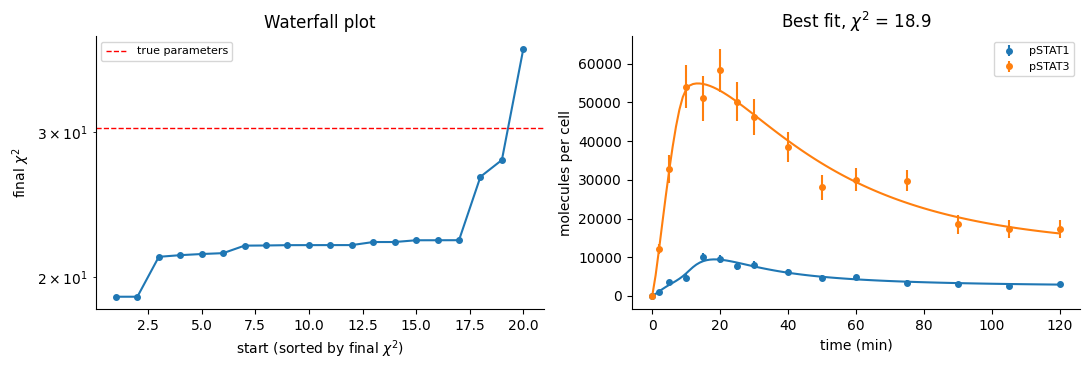

In [12]:
result_high = multistart(problem_high, n_starts=20)
x_best = result_high.optimize_result.list[0]['x']

def plot_waterfall(result, ax, chi2_ref=None):
    c = 2 * np.array([r['fval'] for r in result.optimize_result.list])
    ax.semilogy(range(1, len(c) + 1), c, 'o-', ms=4)
    if chi2_ref is not None:
        ax.axhline(chi2_ref, color='r', ls='--', lw=1, label='true parameters')
        ax.legend(fontsize=8)
    ax.set_xlabel('start (sorted by final $\\chi^2$)'); ax.set_ylabel('final $\\chi^2$')
    ax.set_title('Waterfall plot')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
plot_waterfall(result_high, ax[0], chi2(problem_high, x_true))
plot_data([high_dose], x_best, ax=ax[1], title=f'Best fit, $\\chi^2$ = {chi2(problem_high, x_best):.1f}')
plt.tight_layout(); save_fig('fit_high')

$\chi^2$ at the best fit (18.9) is *lower* than at the true parameters (30.3). That is expected: with noisy data, the optimizer finds parameters that fit this particular noise. Both values are close to the number of data points (28), which is what a correct model with correct error bars should give. The waterfall plot shows most starts converging to nearly the same $\chi^2$, so the optimizer finds the best fit reliably.

Now compare the estimates with the truth. We plot every start that fits essentially as well as the best one ($\Delta\chi^2 < 4$): these are all parameter sets the data cannot distinguish.

,true,best fit,error,spread (good fits)
kon,7.00,7.18,0.18,0.87
koff,-3.00,-4.00,-1.00,0.73
kS1on,5.48,7.13,1.66,0.72
kS1off,0.00,-0.75,-0.75,4.56
kS3on,6.00,8.00,2.00,0.48
kS3off,-0.30,0.40,0.70,3.91
kact,-0.70,0.66,1.36,2.33
kdiss,-0.30,-1.53,-1.23,2.53
kS1dephos,-2.70,-2.51,0.19,0.20
kS3dephos,-2.52,-3.20,-0.68,0.84


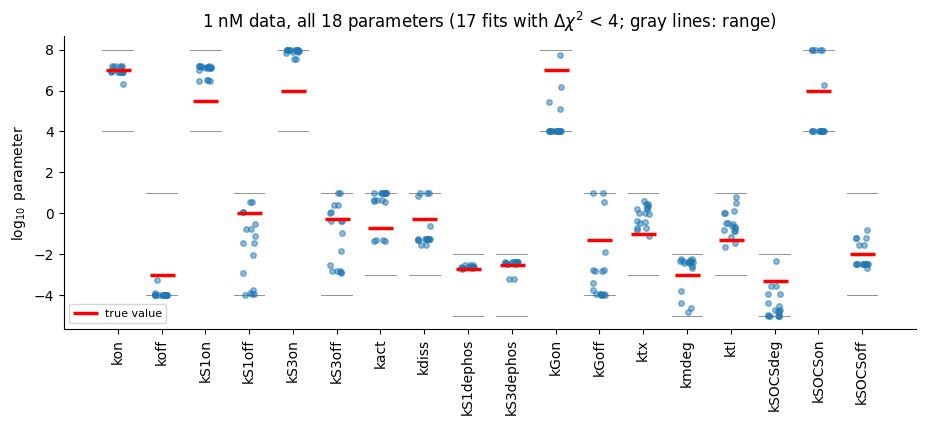

In [13]:
def plot_recovery(result, names=rates, title='', dchi2=4.0, ax=None):
    fbest = result.optimize_result.list[0]['fval']
    good = np.array([r['x'] for r in result.optimize_result.list if 2 * (r['fval'] - fbest) < dchi2])
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 3.8))
    idx = [rates.index(p) for p in names]
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(good))
    for j in range(len(names)):
        ax.plot([j - 0.35, j + 0.35], [lb[idx[j]]] * 2, color='gray', lw=0.6)
        ax.plot([j - 0.35, j + 0.35], [ub[idx[j]]] * 2, color='gray', lw=0.6)
        ax.plot(j + jitter, good[:, j], 'o', color='C0', alpha=0.5, ms=4)
    ax.plot(range(len(names)), x_true[idx], 'r_', ms=18, mew=2.5, label='true value')
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90)
    ax.set_ylabel(r'$\log_{10}$ parameter'); ax.legend(loc='lower left', fontsize=8)
    ax.set_title(f'{title} ({len(good)} fits with $\\Delta\\chi^2$ < {dchi2:g}; gray lines: range)')
    return good

good_high = plot_recovery(result_high, title='1 nM data, all 18 parameters')
save_fig('recovery_high')
pd.DataFrame({'true': x_true, 'best fit': x_best, 'error': x_best - x_true,
              'spread (good fits)': good_high.max(0) - good_high.min(0)}, index=rates).round(2)

The fit is excellent, yet most parameters are not recovered.

- Only `kS1dephos` is pinned down near its true value across all good fits (a spread of 0.2 in $\log_{10}$). `kon` is close, but varies by almost a factor of 10.
- Some parameters are consistently *wrong*: `kS3on` sits at the upper bound in every good fit (the true value is $10^6$), and `koff` at the lower bound.
- Others (`kS1off`, `kS3off`, `kGoff`, `kSOCSon`) scatter across most of their ranges.

This is what the FIM predicted: only about 7 combinations of parameters are constrained by these data, and the individual parameters that make up the other combinations wander.

A good fit does not mean good parameter estimates.

## 6. Profile likelihoods

Scatter across multistart fits is suggestive, but a more careful test is the **profile likelihood**. For parameter $p_i$, we fix it at a series of values and re-optimize all the others each time:

$$\mathrm{PL}(p_i) = \min_{p_{j \ne i}} \chi^2(\mathbf{p}).$$

If the profile rises steeply on both sides of the optimum, the parameter is identifiable, and the values where $\chi^2$ rises by 3.84 above the minimum bound its 95% confidence interval. If the profile stays flat to a bound, the data put no limit on the parameter in that direction: the other parameters compensate.

The algorithm is simple enough to write out. We put 13 points across each parameter's range, start at the point nearest the best fit, and walk outward in both directions, starting each fit from the solution at the previous point. Each point is a fit of the other 17 parameters, so we profile only four parameters. (pyPESTO has a more careful profiler, `pypesto.profile`, which chooses its own step sizes; it is more accurate and much slower.)

Profiles computed in 134 s


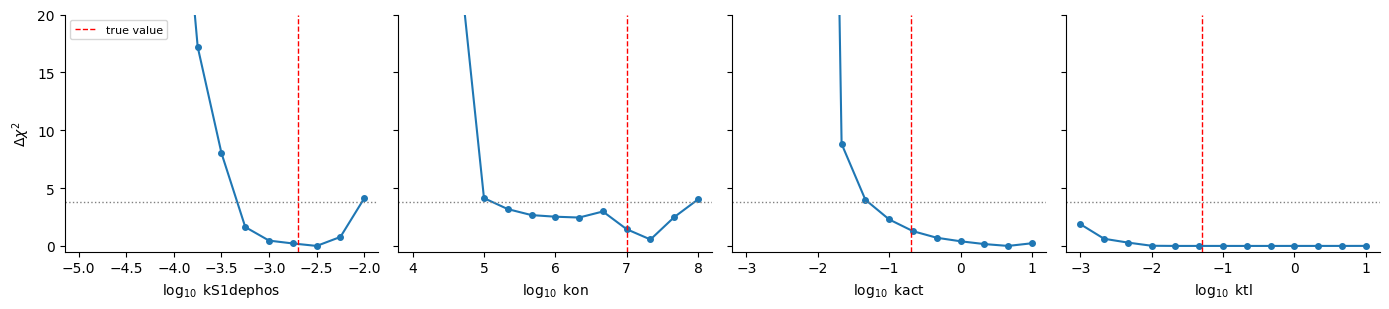

In [14]:
from scipy.optimize import least_squares

def profile_parameter(problem, x_opt, name, n_points=13, max_nfev=60):
    """Profile chi^2 for one parameter on a grid across its range."""
    i = problem.x_names.index(name)
    lo, hi = np.delete(problem.lb, i), np.delete(problem.ub, i)
    grid = np.linspace(problem.lb[i], problem.ub[i], n_points)
    prof = np.full(n_points, np.nan)

    def fit_others(xi, start):
        r = lambda z: problem.res_fun(np.insert(z, i, xi))
        J = lambda z: np.delete(problem.jac_fun(np.insert(z, i, xi)), i, axis=1)
        start = np.clip(start, lo + 1e-9, hi - 1e-9)
        sol = least_squares(r, start, jac=J, bounds=(lo, hi), method='trf', max_nfev=max_nfev)
        return 2 * sol.cost, sol.x

    k0 = np.argmin(np.abs(grid - x_opt[i]))
    for steps in (range(k0, n_points), range(k0 - 1, -1, -1)):   # walk up, then down
        start = np.delete(x_opt, i)
        for k in steps:
            prof[k], start = fit_others(grid[k], start)
    return grid, prof

to_profile = ['kS1dephos', 'kon', 'kact', 'ktl']
chi2_best = chi2(problem_high, x_best)
t0 = time.time()
profiles = {p: profile_parameter(problem_high, x_best, p) for p in to_profile}
print(f'Profiles computed in {time.time() - t0:.0f} s')

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, p in zip(axes, to_profile):
    grid, prof = profiles[p]
    a.plot(grid, prof - min(chi2_best, np.nanmin(prof)), 'o-', ms=4)
    a.axhline(3.84, color='gray', ls=':', lw=1)
    a.axvline(x_true[rates.index(p)], color='r', ls='--', lw=1, label='true value')
    a.set_xlabel(f'$\\log_{{10}}$ {p}'); a.set_ylim(-0.5, 20)
axes[0].set_ylabel(r'$\Delta\chi^2$'); axes[0].legend(fontsize=8)
plt.tight_layout(); save_fig('profiles_high')

The dashed red lines are the true values and the dotted line is the 95% threshold.

- `kS1dephos` is bounded on both sides, and the true value lies inside the interval where $\Delta\chi^2 < 3.84$.
- `kon` and `kact` are bounded on one side only. The data rule out slow ligand binding (`kon` below about $10^5$ M⁻¹ s⁻¹) and a slow kinase, but any faster value fits about as well, because other parameters compensate.
- `ktl` is flat over its whole range, as it must be, since `ktx` can always compensate.

The grid is coarse (13 points), so the ends of the intervals are approximate. Points slightly above zero near the optimum are where the inner fit stopped short of the true minimum.

## 7. A tempting shortcut: fix the insensitive parameters

If some parameters barely affect the outputs, why not fix them at a reasonable guess and fit only the rest? This reduces the number of parameters and speeds up fitting. The catch is the word *reasonable*. We know only the ranges, so the natural guess is the middle of each range.

Here we fix the parameters whose local sensitivity was below 0.1 for both outputs, and fit the others.

fixed at range centers: ['koff', 'kdiss', 'kGon', 'kGoff']


15 starts in 78 s; best chi2 = 24.0; 13 starts within 4 of the best


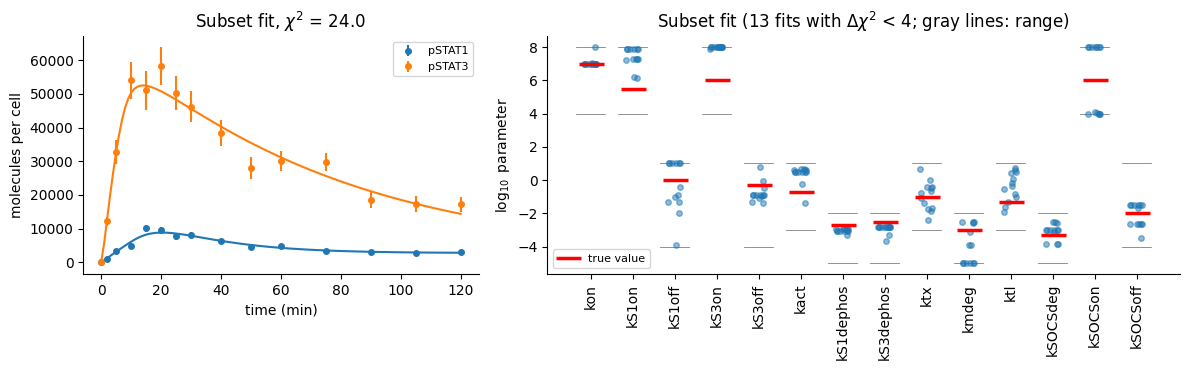

In [15]:
insensitive = list(S_rms.index[S_rms.max(axis=1) < 0.1])
sensitive = [p for p in rates if p not in insensitive]
print('fixed at range centers:', insensitive)
fixed = {p: x_center[rates.index(p)] for p in insensitive}

problem_sub = make_problem([high_dose], free=sensitive, fixed=fixed)
result_sub = multistart(problem_sub, n_starts=15)
x_sub = result_sub.optimize_result.list[0]['x']

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1.6]})
model.set_params({p: 10.0 ** v for p, v in fixed.items()})
plot_data([high_dose], x_sub, names=sensitive, ax=ax[0],
          title=f'Subset fit, $\\chi^2$ = {chi2(problem_sub, x_sub):.1f}')
plot_recovery(result_sub, names=sensitive, title='Subset fit', ax=ax[1])
plt.tight_layout(); save_fig('subset_fit')

The local analysis ranked `koff`, `kdiss`, `kGon`, and `kGoff` as insensitive, so we fixed them at the centers of their ranges. The fit still looks good: $\chi^2$ = 24.0, against 18.9 for the full fit. But the fixed `koff` = $10^{-1.5}$ s⁻¹ is 30 times the true value. With that off-rate only about a quarter of the receptors are occupied at 1 nM, and the fit compensates by changing other parameters: `kact`, for example, is pushed well above its true value in every good fit. The estimates are biased, and nothing in the fit warns you.

`koff` was insensitive *at the true value*, where the receptors are saturated. At the value we fixed it to, it is not. Local sensitivity at one point cannot promise that a parameter is safe to fix; the global analysis, which ranked `koff` first, was the better guide.

A safer use of sensitivity analysis is the one in Sections 5 and 6: fit everything, then report only the parameters (or combinations) that the profiles show are identifiable.

## 8. Designing a better experiment

The 1 nM data leave ligand binding unconstrained, because the receptors saturate almost at once. A dose-response experiment should help: at low ligand concentrations the rate of receptor occupancy, and everything downstream of it, depends on `kon` and `koff`.

We can test this *before* doing the experiment by computing the FIM for the proposed design.

combinations with eigenvalue > 1: 1 nM only 7, three doses 10


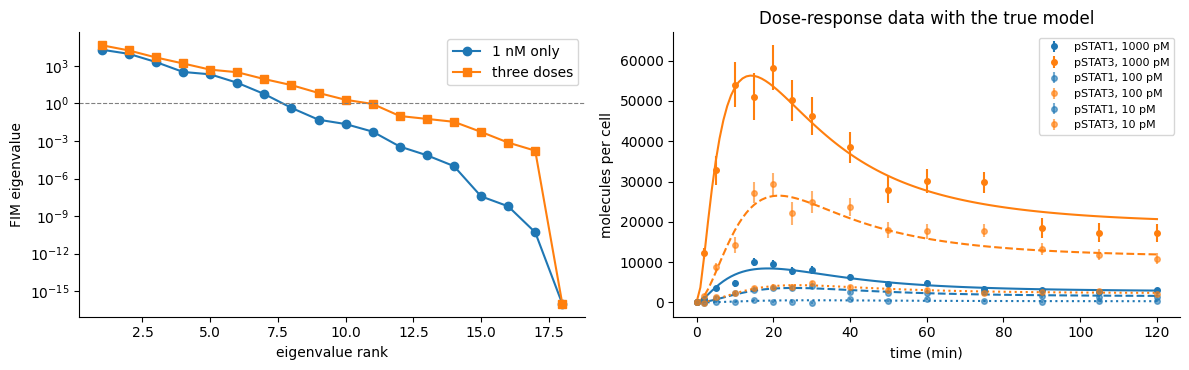

In [16]:
experiments_all = [get_experiment(L) for L in doses]
J_all = np.vstack([jacobian(x_true, e) for e in experiments_all])
eig_all, _ = fim_eigen(J_all)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].semilogy(range(1, 19), np.maximum(eigvals[::-1], 1e-16), 'o-', label='1 nM only')
ax[0].semilogy(range(1, 19), np.maximum(eig_all[::-1], 1e-16), 's-', label='three doses')
ax[0].axhline(1, color='gray', ls='--', lw=0.8)
ax[0].set_xlabel('eigenvalue rank'); ax[0].set_ylabel('FIM eigenvalue'); ax[0].legend()
plot_data(experiments_all, x_true, ax=ax[1], title='Dose-response data with the true model')
plt.tight_layout(); save_fig('design_fim')
print(f'combinations with eigenvalue > 1: 1 nM only {np.sum(eigvals > 1)}, three doses {np.sum(eig_all > 1)}')

The three-dose design raises the information in most directions, by several orders of magnitude for the sloppy ones, and the number of combinations with eigenvalue above 1 goes from 7 to 10. The structural direction `ktx`/`ktl` stays at zero: no experiment that measures only pSTAT can fix it.

Now we refit all 18 parameters to the three data sets.

84 data points; chi2 at the true parameters = 81.7


12 starts in 167 s; best chi2 = 68.1; 9 starts within 4 of the best


,true,"spread, 1 nM only","spread, three doses"
kon,7.00,0.87,0.08
koff,-3.00,0.73,0.31
kS1on,5.48,0.72,2.46
kS1off,0.00,4.56,3.20
kS3on,6.00,0.48,2.45
kS3off,-0.30,3.91,3.88
kact,-0.70,2.33,2.20
kdiss,-0.30,2.53,2.42
kS1dephos,-2.70,0.20,0.19
kS3dephos,-2.52,0.84,0.11


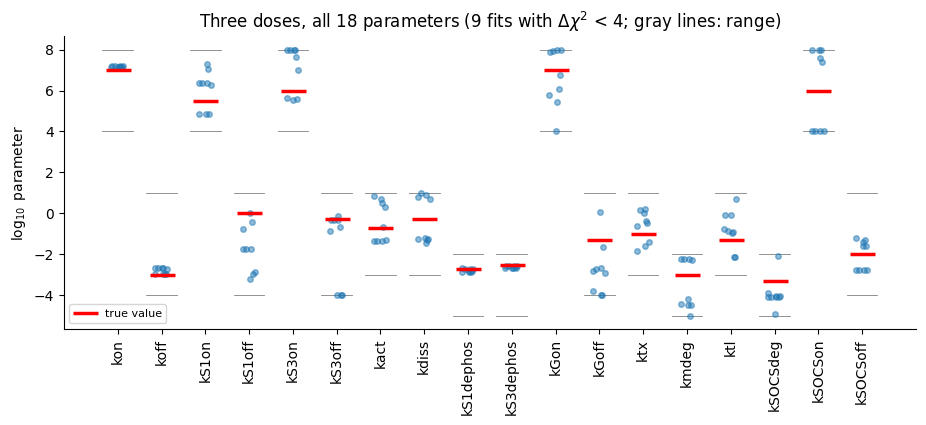

In [17]:
problem_all = make_problem(experiments_all)
print(f'{3 * n_data} data points; chi2 at the true parameters = {chi2(problem_all, x_true):.1f}')
result_all = multistart(problem_all, n_starts=12)

good_all = plot_recovery(result_all, title='Three doses, all 18 parameters')
save_fig('recovery_all')
pd.DataFrame({'true': x_true,
              'spread, 1 nM only': good_high.max(0) - good_high.min(0),
              'spread, three doses': good_all.max(0) - good_all.min(0)}, index=rates).round(2)

With the dose-response data, ligand binding is recovered: `koff`, which sat at its lower bound with one dose, is now pinned near its true value, and `kon` is tighter. Both dephosphorylation rates are well determined. The receptor docking cycle (`kS1on`, `kS1off`, `kS3on`, `kS3off`, `kdiss`) and the SOCS3 loop are still poorly determined: pSTAT time courses tell us how fast each STAT is phosphorylated, but not the individual steps that set that rate. Measuring something closer to those steps, such as receptor-bound STAT or *SOCS3* mRNA, would be the next experiment to consider.

## Summary

- **Sensitivity analysis** shows which parameters affect the outputs you can measure. Local analysis is cheap and exact at one point; global analysis tells you whether the conclusions hold across the plausible range.
- **Identifiability** is about combinations of parameters. The FIM eigenvalues predict which combinations the data constrain, and can be computed before collecting data.
- **Multistart fitting** finds the best fit reliably, but many parameter sets fit equally well. Look at the spread across good fits and at **profile likelihoods** before believing any estimate.
- **Fixing parameters** is safe only if they are insensitive at the values you fix them to.
- When parameters are not identifiable, the analysis tells you **which new experiment** would help, and you can test the design on the model first.

## Exercises

1. Change the noise level to 5% and to 20%. How do the FIM eigenvalues and the spread of good fits change?
2. Replace `ktx` and `ktl` by their product in the model. Is the product identifiable from the 1 nM data?
3. Add `SOCS` (total SOCS3 protein) as a measured output at 1 nM. Which parameters become identifiable?
4. Simulate a SOCS3 knockout (`G0 = 0`) with each of the good fits from Section 5. Do the fits agree on the prediction? What does this say about using a sloppy model for prediction?